In [1]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages.utils import trim_messages, count_tokens_approximately

In [2]:
load_dotenv()

True

In [3]:
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [4]:
MAX_TOKENS = 150

In [5]:
# Node
def call_model(state: MessagesState):

    # Trim conversations history -> last N messages that fit within the token budget
    messages = trim_messages(
        state["messages"],
        strategy="last",
        token_counter=count_tokens_approximately,
        max_tokens=MAX_TOKENS
    )

    print("Current Token Count:", count_tokens_approximately(messages=messages))

    for message in messages:
        content = message.content

        if isinstance(content, str):
            print(content)

        elif isinstance(content, list):
            for block in content:
                if isinstance(block, dict) and block.get("type") == "text":
                    print(block["text"])
                else:
                    print(block)

        print("-" * 120)

    response = llm.invoke(messages)

    return {"messages": [response]}


In [6]:
builder = StateGraph(MessagesState)

builder.add_node("call_model", call_model)

builder.add_edge(START, "call_model")

In [7]:
checkpointer = InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)

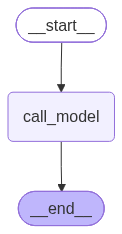

In [8]:
graph

In [9]:
CONFIG = {"configurable": {"thread_id": "chat-1"}}

result = graph.invoke(
    {"messages": [{"role": "user", "content": "Hi, My name is Saksham."}]},
    config=CONFIG
)

result["messages"][-1].content[0]["text"]

Current Token Count: 10
Hi, My name is Saksham.
------------------------------------------------------------------------------------------------------------------------


"Hi Saksham! It's nice to meet you. How can I help you today?"

In [10]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "I am learning LangGraph."}]},
    config=CONFIG
)

result["messages"][-1].content[0]["text"]

Current Token Count: 41
Hi, My name is Saksham.
------------------------------------------------------------------------------------------------------------------------
Hi Saksham! It's nice to meet you. How can I help you today?
------------------------------------------------------------------------------------------------------------------------
I am learning LangGraph.
------------------------------------------------------------------------------------------------------------------------


"That's awesome, Saksham! LangGraph is a fantastic tool for building stateful, multi-actor applications with LLMs—especially if you're looking to move beyond simple chains into complex agent workflows with loops and memory.\n\nWhat kind of project are you working on, or are you just getting started with the basics? I can help you with:\n\n*   Understanding core concepts (Nodes, Edges, State)\n*   Writing code for graphs and state management\n*   Debugging existing workflows\n*   Setting up agent loops (like ReAct agents)\n\nWhere would you like to start?"

In [11]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "Can you explain short term memory?"}]},
    config=CONFIG
)

result["messages"][-1].content[0]["text"]

Current Token Count: 13
Can you explain short term memory?
------------------------------------------------------------------------------------------------------------------------


'**Short-term memory (STM)** is the brain’s system for temporarily holding and processing information in our conscious awareness. Think of it as the brain\'s **RAM (Random Access Memory)**—it is used to handle information you need right now, but it doesn\'t store it permanently.\n\nHere is a breakdown of how short-term memory works, its limits, and how it differs from other types of memory.\n\n---\n\n### 1. Key Characteristics of Short-Term Memory\n\n* **Limited Capacity:** Unlike your long-term memory (which has a seemingly infinite capacity), short-term memory can only hold a small amount of information at once. \n* **Limited Duration:** Information in STM fades very quickly. Without conscious effort, it typically lasts only about **15 to 30 seconds**.\n* **Vulnerable to Distraction:** Because it relies on active attention, any interruption can easily knock information out of short-term memory (like forgetting what you were about to say when someone interrupts you).\n\n### 2. The Cla

In [12]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "What is my name?"}]},
    config=CONFIG
)

result["messages"][-1].content[0]["text"]

Current Token Count: 8
What is my name?
------------------------------------------------------------------------------------------------------------------------


"I don't know your name because you haven't told me yet! What should I call you?"

In [13]:
state = graph.get_state({"configurable": {"thread_id": "chat-1"}})

for item in state.values["messages"]:
    content = item.content

    if isinstance(content, str):
        print(content)

    elif isinstance(content, list):
        for block in content:
            if isinstance(block, dict) and block.get("type") == "text":
                print(block["text"])

    print("-" * 150)


Hi, My name is Saksham.
------------------------------------------------------------------------------------------------------------------------------------------------------
Hi Saksham! It's nice to meet you. How can I help you today?
------------------------------------------------------------------------------------------------------------------------------------------------------
I am learning LangGraph.
------------------------------------------------------------------------------------------------------------------------------------------------------
That's awesome, Saksham! LangGraph is a fantastic tool for building stateful, multi-actor applications with LLMs—especially if you're looking to move beyond simple chains into complex agent workflows with loops and memory.

What kind of project are you working on, or are you just getting started with the basics? I can help you with:

*   Understanding core concepts (Nodes, Edges, State)
*   Writing code for graphs and state managemen